MLP (3 layers) run 5/5: 100%|██████████| 10000/10000 [00:02<00:00, 3986.33it/s, loss=0.0377]


saved results\test2_lipschitz.png
saved results\test2_lipschitz.pdf


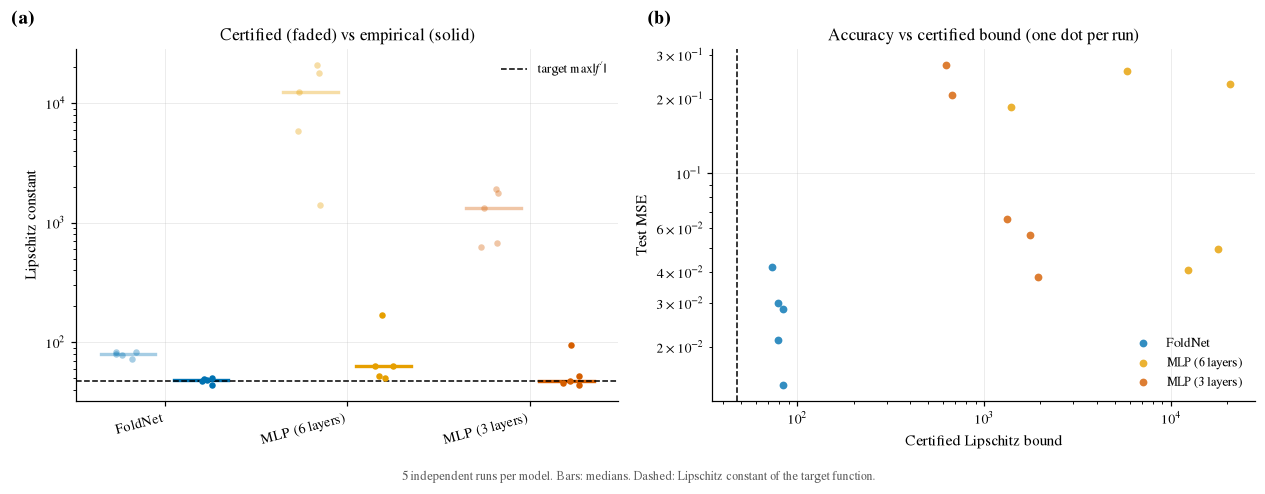

| Model | Params | Certified $L$ | Empirical $L$ | Tightness (emp./cert.) | Test MSE |
|---|---|---|---|---|---|
| FoldNet | 673 | 79.2 [78.6, 83.2] | 47.9 [47.8, 48.9] | 0.604 [0.602, 0.606] | 2.84e-02 [2.13e-02, 3.02e-02] |
| MLP (6 layers) | 694 | 12341.9 [5838.8, 17754.0] | 63.1 [51.8, 63.3] | 0.008 [0.004, 0.011] | 1.85e-01 [4.95e-02, 2.28e-01] |
| MLP (3 layers) | 664 | 1319.6 [671.4, 1764.1] | 47.9 [45.4, 52.1] | 0.039 [0.025, 0.073] | 6.58e-02 [5.65e-02, 2.08e-01] |
saved results\test2_lipschitz_table.{md,tex,csv}


In [1]:
"""Test 2: certified vs empirical Lipschitz constant, and the accuracy it costs."""
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from foldnet_lib import FoldNet, DEV
from foldnet_bench import standard_builders, benchmark
import foldnet_viz as V

N_RUNS = 5
STEPS = 10000
D, DEPTH, K = 32, 6, 2
USE = ["FoldNet", "MLP (6 layers)", "MLP (3 layers)"]    # models with a simple certificate
RESULTS_DIR = "results"


def f(x):
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)


def spectral(w):
    return torch.linalg.matrix_norm(w, ord=2).item()


@torch.no_grad()
def certified_lip(model):
    """FoldNet: ||W_in|| ||W_out|| (Theorem 3.4(c)). MLP: product of layer spectral norms."""
    if isinstance(model, FoldNet):
        return spectral(model.inp.weight) * spectral(model.out.weight)
    L = 1.0
    for layer in model.net:
        if isinstance(layer, nn.Linear):
            L *= spectral(layer.weight)
    return L


def empirical_lip(model, n=40001):
    x = torch.linspace(-1, 1, n, device=DEV).unsqueeze(1).requires_grad_(True)
    g = torch.autograd.grad(model(x).sum(), x)[0]
    return g.abs().max().item()


if __name__ == "__main__":
    V.set_style()
    all_b, target = standard_builders(1, 1, D, DEPTH, K)
    builders = {n: all_b[n] for n in USE}
    res, xs, ys = benchmark(builders, f, n_runs=N_RUNS, steps=STEPS, keep_models=True)

    xg = np.linspace(-1, 1, 200001)
    target_lip = float(np.abs(20 * np.cos(20 * xg) + 27.5 * np.cos(55 * xg)).max())

    cert, emp, mse, npar = {}, {}, {}, {}
    for n in USE:
        cert[n] = np.array([certified_lip(r["model"]) for r in res[n]])
        emp[n] = np.array([empirical_lip(r["model"]) for r in res[n]])
        mse[n] = np.array([r["mse"] for r in res[n]])
        npar[n] = res[n][0]["n_params"]

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
    ax = axes[0]
    rng = np.random.default_rng(0)
    for i, n in enumerate(USE):
        c = V.color_for(n)
        for off, vals, alpha in [(-0.2, cert[n], 0.35), (0.2, emp[n], 1.0)]:
            ax.scatter(i + off + rng.uniform(-0.07, 0.07, len(vals)), vals, s=18, color=c,
                       alpha=alpha, linewidths=0, zorder=3)
            ax.plot([i + off - 0.15, i + off + 0.15], [np.median(vals)] * 2, color=c,
                    lw=2.2, alpha=alpha)
    ax.axhline(target_lip, color="k", ls="--", lw=1, label=r"target $\max|f'|$")
    ax.set_yscale("log")
    ax.set_xticks(range(len(USE)))
    ax.set_xticklabels(USE, rotation=15, ha="right")
    ax.set_ylabel("Lipschitz constant")
    ax.set_title("Certified (faded) vs empirical (solid)")
    ax.legend()
    V.panel_label(ax, "(a)")

    ax = axes[1]
    for n in USE:
        ax.scatter(cert[n], mse[n], s=26, color=V.color_for(n), label=n, linewidths=0, alpha=0.8)
    ax.axvline(target_lip, color="k", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Certified Lipschitz bound")
    ax.set_ylabel("Test MSE")
    ax.set_title("Accuracy vs certified bound (one dot per run)")
    ax.legend()
    V.panel_label(ax, "(b)")

    fig.text(0.5, -0.03, f"{N_RUNS} independent runs per model. Bars: medians. "
             "Dashed: Lipschitz constant of the target function.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test2_lipschitz", RESULTS_DIR)
    plt.show()

    tab = V.Table(["Model", "Params", "Certified $L$", "Empirical $L$",
                   "Tightness (emp./cert.)", "Test MSE"])
    for n in USE:
        tab.add(n, npar[n], V.med_iqr(cert[n], lambda v: f"{v:.1f}"),
                V.med_iqr(emp[n], lambda v: f"{v:.1f}"),
                V.med_iqr(emp[n] / cert[n], lambda v: f"{v:.3f}"), V.med_iqr(mse[n]))
    tab.show()
    tab.save("test2_lipschitz_table", RESULTS_DIR,
             caption=(f"Certified and empirical Lipschitz constants over {N_RUNS} runs, median "
                      f"[Q1, Q3]. The target has Lipschitz constant {target_lip:.1f}."),
             label="tab:lipschitz")